In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# definimos nuestras imagenes como matrices 8x8

J_img = np.array([
    [0,0,1,1,1,1,1,0],
    [0,0,0,0,0,1,0,0],
    [0,0,0,0,0,1,0,0],
    [0,0,0,0,0,1,0,0],
    [0,0,0,0,0,1,0,0],
    [0,1,0,0,0,1,0,0],
    [0,1,0,0,0,1,0,0],
    [0,0,1,1,1,0,0,0],
])
 
H_img = np.array([
    [0,1,0,0,0,0,1,0],
    [0,1,0,0,0,0,1,0],
    [0,1,0,0,0,0,1,0],
    [0,1,1,1,1,1,1,0],
    [0,1,0,0,0,0,1,0],
    [0,1,0,0,0,0,1,0],
    [0,1,0,0,0,0,1,0],
    [0,1,0,0,0,0,1,0],
])


def img2vec(img): 
    return np.where(img.flatten() == 1, 1, -1)

def vec2img(q, n=8, m=8):
    return q.reshape(n, m)

 # definimos la matrix X (tamaño 2x64)
X = np.array([img2vec(J_img), img2vec(H_img)])  
P, N = X.shape
print("shape de X:", P ,",", N)

shape de X: 2 , 64


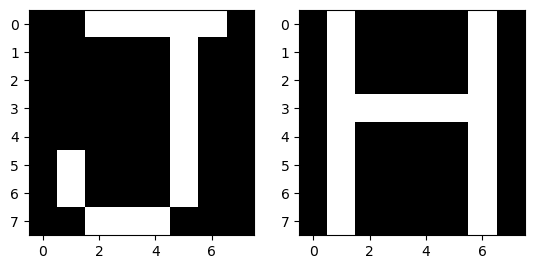

In [3]:
# visualización de las letras

plt.subplot(1, 2, 1)
plt.imshow(J_img, cmap="gray")

plt.subplot(1, 2, 2)
plt.imshow(H_img, cmap="gray")

plt.show()

In [4]:
# agregar ruido al vector s, con un porcentaje de l 25%
def ruido(s, frac=0.20, rng=None):
    rng = np.random.default_rng(rng)
    s_ruido = s.astype(float).copy()
    n_flip = int(round(frac * len(s)))
    idx = rng.choice(len(s), n_flip, replace=False)
    s_ruido[idx] *= -1
    return s_ruido

In [5]:
# aplicar ruido 
J_ruido = ruido(img2vec(J_img))
H_ruido = ruido(img2vec(H_img))

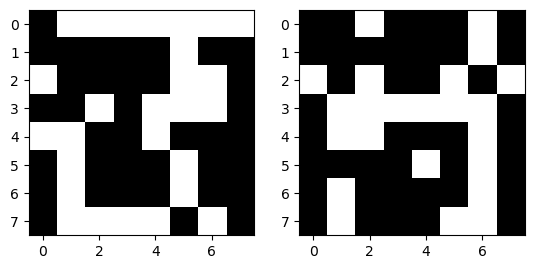

In [6]:
# visualizar patrones con ruido
plt.subplot(1, 2, 1)
plt.imshow(vec2img(J_ruido), cmap="gray", vmin=-1, vmax=1)


plt.subplot(1, 2, 2)
plt.imshow(vec2img(H_ruido), cmap="gray", vmin=-1, vmax=1)
plt.show()

In [7]:
# ciclo de recuperación 
def recuperar(q0, X, beta, alpha=1.0, max_iter=100, tol=1e-8):
    q = q0.astype(float).copy()
    estados = [q.copy()]
    energias = [energia(q, X, beta)]
    for t in range(max_iter):
        q_nuevo = actualizar(q, X, beta, alpha)
        estados.append(q_nuevo.copy())
        energias.append(energia(q_nuevo, X, beta))
        if np.linalg.norm(q_nuevo - q) < tol:     # convergencia
            q = q_nuevo
            break
        q = q_nuevo
    return q, np.array(energias), estados

In [8]:
# definimos las funciones necesarias 

def energia(q, X, beta):
    # E(q) = 1/2 sum q_i^2 - (1/beta) ln( sum_mu exp(beta * x_mu . q) )
    z = beta * (X @ q)
    lse = np.max(z) + np.log(np.sum(np.exp(z - np.max(z))))   # log-sum-exp estable
    return 0.5 * q @ q - lse / beta

def actualizar(q, X, beta, alpha=1.0):
    # q^(t+1) = q^(t) - alpha * dE/dq ;  con alpha = 1 queda q^(t+1) = X^T softmax(beta X q^(t))
    return q - alpha * gradiente(q, X, beta)

def gradiente(q, X, beta):
    # dE/dq_i = q_i - sum_mu p_mu x_mu,i ,  con p = softmax(beta * X q)
    p = softmax(beta * (X @ q))
    return q - X.T @ p

def softmax(z):
    z = z - np.max(z)  
    e = np.exp(z)
    return e / e.sum()

In [ ]:
patron = X[0]           # J
frac   = 0.25
beta   = 1.0

q0 = ruido(patron, frac, rng=1)
q_final, E, estados = recuperar(q0, X, beta, alpha=1.0, max_iter=100)


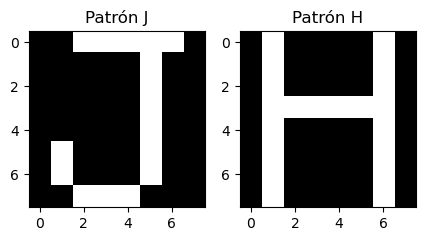

Iteraciones: 3
Acierto: 100.0 %


In [15]:
def binarizar(q):
    return np.where(q >= 0, 1, -1)
 
def porcentaje_acierto(q, patron):
    return 100 * np.mean(binarizar(q) == patron)
 
fig, ax = plt.subplots(1, 2, figsize=(5, 2.6))
for k, nombre in enumerate(["J", "H"]):
    ax[k].imshow(vec2img(X[k]), cmap="gray", vmin=-1, vmax=1)
    ax[k].set_title(f"Patrón {nombre}")
plt.show()
 
print(f"Iteraciones: {len(E)-1}")
print(f"Acierto: {porcentaje_acierto(q_final, patron):.1f} %")
 

/var/folders/mw/vslmgkkn541fjwd3442_wk200000gn/T/ipykernel_2729/2866640887.py:6: UserWarning: Adding colorbar to a different Figure <Figure size 1200x320 with 5 Axes> than <Figure size 1200x320 with 5 Axes> which fig.colorbar is called on.
  fig.colorbar(im, ax=ax, shrink=0.8)


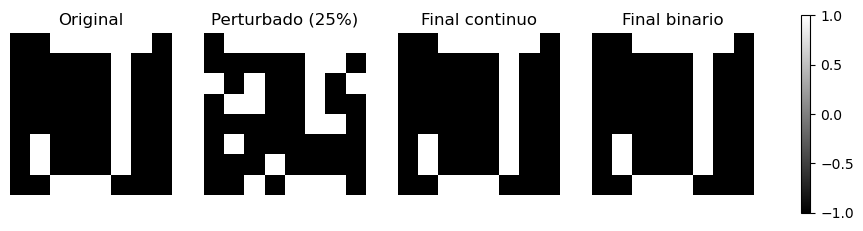

Iteraciones: 3
Acierto: 100.0 %


In [20]:
ig, ax = plt.subplots(1, 4, figsize=(12, 3.2))
for a, (img, titulo) in zip(ax, paneles):
    im = a.imshow(vec2img(img), cmap="gray", vmin=-1, vmax=1)
    a.set_title(titulo)
    a.axis("off")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()
 
print(f"Iteraciones: {len(E)-1}")
print(f"Acierto: {porcentaje_acierto(q_final, patron):.1f} %")


beta = 0.001  iteraciones = 7   E_final =  -711.147  pesos (J, H) = (0.500, 0.500)  acierto = 100.0 %  ambiguos = 28
beta = 0.01   iteraciones = 16  E_final =   -87.315  pesos (J, H) = (0.500, 0.500)  acierto = 100.0 %  ambiguos = 28
beta = 0.05   iteraciones = 28  E_final =   -33.465  pesos (J, H) = (0.907, 0.093)  acierto = 100.0 %  ambiguos = 0
beta = 0.1    iteraciones = 9   E_final =   -32.038  pesos (J, H) = (0.996, 0.004)  acierto = 100.0 %  ambiguos = 0
beta = 0.5    iteraciones = 3   E_final =   -32.000  pesos (J, H) = (1.000, 0.000)  acierto = 100.0 %  ambiguos = 0
beta = 1      iteraciones = 3   E_final =   -32.000  pesos (J, H) = (1.000, 0.000)  acierto = 100.0 %  ambiguos = 0
beta = 10     iteraciones = 2   E_final =   -32.000  pesos (J, H) = (1.000, 0.000)  acierto = 100.0 %  ambiguos = 0


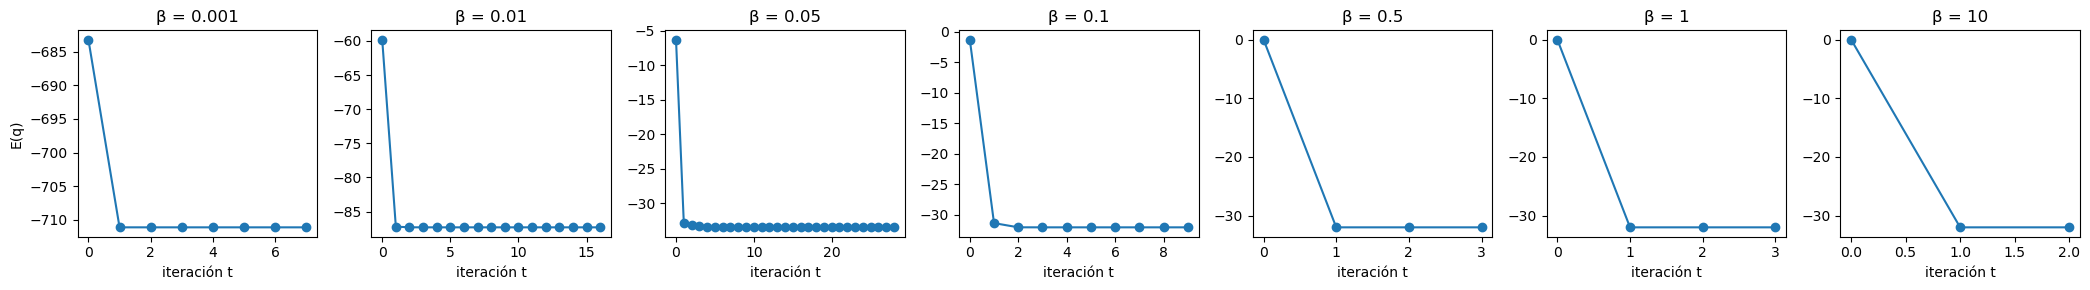

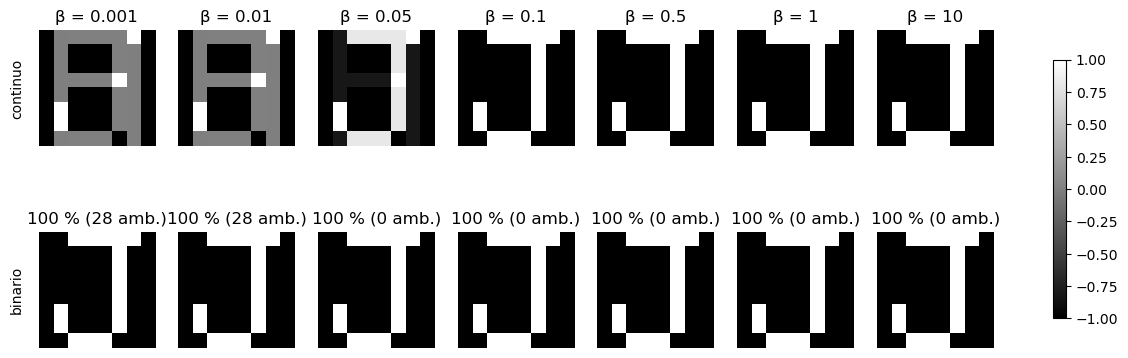

In [27]:
# para diferentes betas 

# %% [celda c1] mismo estado inicial, distintos beta
betas  = [0.001, 0.01, 0.05, 0.1, 0.5, 1, 10]
patron = X[0]                                  # J
frac   = 0.25
q0     = ruido(patron, frac, rng=1)    # el MISMO estado perturbado para todos los beta

# píxeles "ambiguos": el estado continuo quedó muy cerca de 0 y su signo no significa nada
def n_ambiguos(q, umbral=0.1):
    return int(np.sum(np.abs(q) < umbral))

resultados = {}
for beta in betas:
    q_final, E, estados = recuperar(q0, X, beta, alpha=1.0, max_iter=100)
    p_final = softmax(beta * (X @ q_final))    # peso que la red le da a cada patrón
    resultados[beta] = dict(q=q_final, E=E, estados=estados, p=p_final)
    print(f"beta = {beta:<6} iteraciones = {len(E)-1:<3} "
          f"E_final = {E[-1]:9.3f}  pesos (J, H) = ({p_final[0]:.3f}, {p_final[1]:.3f})  "
          f"acierto = {porcentaje_acierto(q_final, patron):5.1f} %  ambiguos = {n_ambiguos(q_final)}")

fig, ax = plt.subplots(1, len(betas), figsize=(3*len(betas), 3))
for a, beta in zip(ax, betas):
    E = resultados[beta]["E"]
    a.plot(range(len(E)), E, "o-")
    a.set_title(f"β = {beta}")
    a.set_xlabel("iteración t")
ax[0].set_ylabel("E(q)")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(2, len(betas), figsize=(2.2*len(betas), 4.8))
for k, beta in enumerate(betas):
    q = resultados[beta]["q"]
    im = ax[0, k].imshow(vec2img(q), cmap="gray", vmin=-1, vmax=1)
    ax[0, k].set_title(f"β = {beta}")
    ax[1, k].imshow(vec2img(binarizar(q)), cmap="gray", vmin=-1, vmax=1)
    ax[1, k].set_title(f"{porcentaje_acierto(q, patron):.0f} % ({n_ambiguos(q)} amb.)")
for a in ax.ravel():
    a.axis("off")
ax[0, 0].text(-1.5, 3.5, "continuo", rotation=90, va="center", ha="right")
ax[1, 0].text(-1.5, 3.5, "binario", rotation=90, va="center", ha="right")
fig.colorbar(im, ax=ax, shrink=0.7)
plt.show()

betas_finos = np.logspace(-3, 1, 60)
pesos_J = []
for beta in betas_finos:
    q_final, _, _ = recuperar(q0, X, beta, alpha=1.0, max_iter=200)
    pesos_J.append(softmax(beta * (X @ q_final))[0])

betas_c  = [0.01, 0.05, 0.1, 1, 10]
fracs    = np.linspace(0, 1, 21)
n_rep    = 50
rng      = np.random.default_rng(0)